# Trabajo final
## Clasificación de perros y gatos

Este notebook es la base común del trabajo.


**Al final de la clase:** rellenad unas preguntas vía MiAulario y entregad una copia del notebook generado.


## 0. Configuración

In [1]:
import os, glob, time
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
#from comprobaciones import comprobar_evaluar   # fichero comprobaciones.py, junto a este notebook

RUTA_DATASET = "dataset"      # carpeta con train/ y test/
CARPETA_CACHE = "cache"       # aquí se guardan los vectores ya calculados
CLASES = ["cat", "dog"]       # 0 = gato, 1 = perro
os.makedirs(CARPETA_CACHE, exist_ok=True)

## 1. Lectura del dataset

Estructura esperada:

```
dataset/
├── train/
│   ├── cat/
│   └── dog/
└── test/
    ├── cat/
    └── dog/
```

La etiqueta de cada imagen sale del nombre de su carpeta: 0 = gato, 1 = perro.

In [2]:
def listar_imagenes(carpeta):
    rutas, etiquetas = [], []
    for etiqueta, clase in enumerate(CLASES):
        ficheros = sorted(glob.glob(os.path.join(carpeta, clase, "*")))
        rutas += ficheros
        etiquetas += [etiqueta] * len(ficheros)
    return rutas, np.array(etiquetas)

rutas_train, y_train = listar_imagenes(os.path.join(RUTA_DATASET, "train"))
rutas_test, y_test = listar_imagenes(os.path.join(RUTA_DATASET, "test"))
print(f"Entrenamiento: {len(rutas_train)} imágenes ({np.sum(y_train == 0)} gatos, {np.sum(y_train == 1)} perros)")
print(f"Test:          {len(rutas_test)} imágenes ({np.sum(y_test == 0)} gatos, {np.sum(y_test == 1)} perros)")

Entrenamiento: 2000 imágenes (1000 gatos, 1000 perros)
Test:          2000 imágenes (1000 gatos, 1000 perros)


¿Tienen todas las imágenes el mismo tamaño?

Anchos entre 42 y 1050 · altos entre 39 y 768


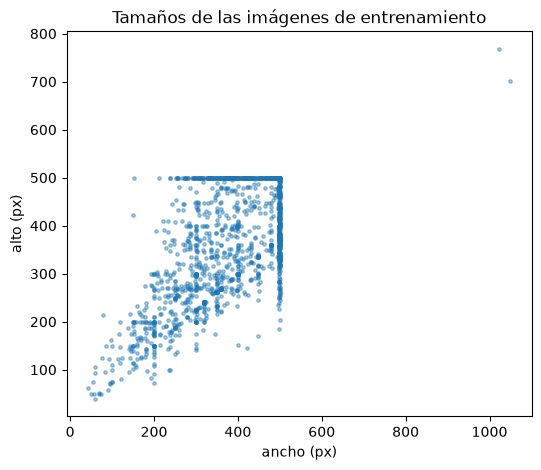

In [3]:
tamanos = np.array([Image.open(r).size for r in rutas_train])   # (ancho, alto), sin decodificar la imagen
plt.figure(figsize=(6, 5))
plt.scatter(tamanos[:, 0], tamanos[:, 1], s=6, alpha=0.4)
plt.xlabel("ancho (px)"); plt.ylabel("alto (px)")
plt.title("Tamaños de las imágenes de entrenamiento")
print("Anchos entre", tamanos[:, 0].min(), "y", tamanos[:, 0].max(), "· altos entre", tamanos[:, 1].min(), "y", tamanos[:, 1].max())

Pensad en esto: ¿el tamaño del descriptor depende del tamaño de la imagen? Todas las imágenes tienen que acabar dando un vector **de la misma longitud**.

## 2. Preprocesado

El preprocesado recibe una imagen BGR tal como la lee OpenCV y devuelve la imagen que verá el descriptor.

Debes decidir si quieres hacer un redimensionado (y a qué dimensión) Después, decidiréis qué otras técnicas de preprocesado podéis utilizar: cambiar de espacio de color, ecualizar, corregir gamma, suavizar… **Un preprocesado no es bueno o malo en abstracto: depende de lo que mide el descriptor.**

In [4]:
def redimensionar(imagen, tam=128):
    filas, columnas = imagen.shape[:2]

    if filas * columnas > tam * tam:
        metodo = cv2.INTER_AREA
    else:
        metodo = cv2.INTER_LINEAR

    imagen_red = cv2.resize(imagen, (tam, tam), interpolation=metodo)
    
    return imagen_red

In [5]:
def preprocesar(imagen, tam=128):
    
    return redimensionar(imagen, tam)

## 3. Paso 1: histograma de color global

Implementad `descriptor_color(img, ...)`. Debe devolver un vector 1D de **longitud fija**, la misma para todas las imágenes, sea cual sea su tamaño. El tamaño del vector vendrá determinado por el número de bins del histograma. Puedes utilizar ese número como parámetro de la función.

Las decisiones son vuestras y tendréis que justificarlas: cuántos intervalos por canal, si los canales van por separado o juntos, si normalizáis el histograma y cómo…

In [6]:
def descriptor_color(imagen, bins=8):
    histogramas = []

    for c in range(3):  # Repettir por cada color
        hist = cv2.calcHist([imagen], [c], None, [bins], [0, 256]).flatten()
        suma = np.sum(hist)
        hp = hist / suma
        histogramas.append(hp)

    vector = np.concatenate(histogramas)
    
    return vector.astype(np.float32)

In [7]:
def sin_preprocesado(img):
    return img

In [8]:
# Comprobación rápida: mismo tamaño de vector para imágenes de tamaños distintos
vectores = [descriptor_color(sin_preprocesado(cv2.imread(r))) for r in rutas_train[:5]]
assert all(np.asarray(v).ndim == 1 for v in vectores), "El descriptor debe devolver un vector 1D"
assert len({np.asarray(v).size for v in vectores}) == 1, "Todas las imágenes deben dar un vector de la misma longitud"
print("Dimensión del vector:", np.asarray(vectores[0]).size)

Dimensión del vector: 24


## 3b. Paso 2: histograma de color por regiones

Dividid la imagen **ya redimensionada** en una rejilla de n × n bloques, calculad vuestro histograma de color en cada uno y concatenad los resultados.


In [9]:
def descriptor_color_regiones(img, n=2):
    bloques = []
    for fila in np.array_split(img, n, axis=0):
        for bloque in np.array_split(fila, n, axis=1):
            bloques.append(descriptor_color(bloque))

    return np.concatenate(bloques)

In [10]:
vectores = [descriptor_color_regiones(redimensionar(cv2.imread(r))) for r in rutas_train[:5]]
assert len({np.asarray(v).size for v in vectores}) == 1, "Todas las imágenes deben dar un vector de la misma longitud"
print("Dimensión del vector por regiones:", np.asarray(vectores[0]).size)

Dimensión del vector por regiones: 96


In [26]:
def descriptor_lbp(img, P=8, R=1, metodo='default', n=1):
    img_gris = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

    codigos = local_binary_pattern(img_gris, P, R, method=metodo).astype(np.int32)

    if metodo == 'default':
        n_bins = 2**P               # 256 con P=8
    elif metodo == 'uniform':
        n_bins = P + 2              # 10 con P=8
    elif metodo == 'nri_uniform':
        n_bins = P * (P - 1) + 3    # 59 con P=8
    else:
        raise ValueError(f"Método no soportado: {metodo}")

    partes = []                                                     # aquí va el histograma de cada bloque
    for fila in np.array_split(codigos, n, axis=0):                 # n franjas horizontales
        for bloque in np.array_split(fila, n, axis=1):              # n bloques por franja
            hist = np.bincount(bloque.ravel(), minlength=n_bins)    # (n_bins,)
            partes.append(hist / hist.sum())                        # normalización L1 por bloque

    return np.concatenate(partes).astype(np.float32)

In [28]:
# LBP 59 global (59 dim)
X_lbp59 = extraer_todas(rutas_train, preprocesar, lambda im: descriptor_lbp(im, metodo="nri_uniform"), nombre="lbp_nri59_p8r1_g128")
ac_lbp59 = evaluar(X_lbp59, y_train)
print(f"LBP 59 global (59 dim): {ac_lbp59.mean():.4f} ± {ac_lbp59.std():.4f}")

# LBP 59 regiones 4x4 (944 dim)
X_lbp59r = extraer_todas(rutas_train, preprocesar, lambda im: descriptor_lbp(im, metodo="nri_uniform", n=4), nombre="lbp_nri59_p8r1_n4_g128")
ac_lbp59r = evaluar(X_lbp59r, y_train)
print(f"LBP 59 regiones 4x4 (944 dim): {ac_lbp59r.mean():.4f} ± {ac_lbp59r.std():.4f}")

Cargado de caché: cache\lbp_nri59_p8r1_g128.npy  (2000, 59)
LBP 59 global (59 dim): 0.6535 ± 0.0215
Cargado de caché: cache\lbp_nri59_p8r1_n4_g128.npy  (2000, 944)
LBP 59 regiones 4x4 (944 dim): 0.7600 ± 0.0146


## 4. Extracción de características (hecho)

`extraer_todas` aplica el preprocesado y el descriptor a una lista de imágenes y devuelve la matriz **X**, con una fila por imagen.

La extracción es la parte lenta, así que guarda el resultado en disco: si la volvéis a llamar con el mismo `nombre`, carga el fichero en lugar de recalcular. **Si cambiáis el preprocesado o el descriptor, cambiad también el nombre** (o borrad el fichero de `cache/`); si no, seguiréis usando los vectores antiguos.

In [11]:
def extraer_todas(rutas, preprocesar, descriptor, nombre=None):
    fichero = os.path.join(CARPETA_CACHE, nombre + ".npy") if nombre else None
    if fichero and os.path.exists(fichero):
        X = np.load(fichero)
        print(f"Cargado de caché: {fichero}  {X.shape}")
        return X

    t0 = time.time()
    filas = []
    for r in rutas:
        img = cv2.imread(r)
        if img is None:
            raise IOError(f"No se puede leer {r}")
        filas.append(np.asarray(descriptor(preprocesar(img)), dtype=np.float32).ravel())
    
    longitudes = {f.size for f in filas}
    if len(longitudes) > 1:
        raise ValueError(f"El descriptor devuelve vectores de longitudes distintas: {sorted(longitudes)}")
    
    X = np.vstack(filas)
    if fichero:
        np.save(fichero, X)
    
    print(f"{len(rutas)} imágenes · vector de {X.shape[1]} dimensiones · {time.time() - t0:.1f} s")
    
    return X

In [31]:
# LBP 59 global (59 dim)
X_lbp59 = extraer_todas(rutas_train, preprocesar, lambda im: descriptor_lbp(im, metodo="nri_uniform"), nombre="lbp_nri59_p8r1_g128")
ac_lbp59 = evaluar(X_lbp59, y_train)
print(f"LBP 59 global (59 dim): {ac_lbp59.mean():.4f} ± {ac_lbp59.std():.4f}\n")

# LBP 59 regiones 4x4 (944 dim)
X_lbp59r = extraer_todas(rutas_train, preprocesar, lambda im: descriptor_lbp(im, metodo="nri_uniform", n=4), nombre="lbp_nri59_p8r1_n4_g128")
ac_lbp59r = evaluar(X_lbp59r, y_train)
print(f"LBP 59 regiones 4x4 (944 dim): {ac_lbp59r.mean():.4f} ± {ac_lbp59r.std():.4f}")

Cargado de caché: cache\lbp_nri59_p8r1_g128.npy  (2000, 59)
LBP 59 global (59 dim): 0.6535 ± 0.0215

Cargado de caché: cache\lbp_nri59_p8r1_n4_g128.npy  (2000, 944)
LBP 59 regiones 4x4 (944 dim): 0.7600 ± 0.0146


## 5. Protocolo de evaluación común

Todas las parejas evaluamos igual:

- **Particiones:** `StratifiedKFold(n_splits=5, shuffle=True, random_state=0)`
- **Modelo:** `StandardScaler` + `SVC(kernel="rbf", C=1, gamma="scale")`, sin ajustar C ni gamma
- **El escalado se ajusta solo con la parte de entrenamiento de cada partición.** Si se ajusta con todos los datos, información de la parte de validación se cuela en el entrenamiento.
- `evaluar` devuelve un array con el acierto de cada una de las 5 particiones, en orden.

Completad `evaluar` y ejecutad después `comprobar_evaluar(evaluar)`: compara vuestros resultados con los del protocolo sobre un conjunto sintético y, si no coinciden, os dice qué puede estar fallando.

In [12]:
def evaluar(X, y):
    particiones = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
    aciertos = []

    for idx_train, idx_val in particiones.split(X, y):
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X[idx_train])
        X_val = scaler.transform(X[idx_val])

        modelo = SVC(kernel="rbf", C=1, gamma="scale")
        modelo.fit(X_train, y[idx_train])
        aciertos.append(modelo.score(X_val, y[idx_val]))
    return np.array(aciertos)

In [21]:
# Color global con 8 bins 
X_g8 = extraer_todas(rutas_train, preprocesar, lambda im: descriptor_color(im, bins=8), nombre="color_bgr_b8_g128")
ac_g8 = evaluar(X_g8, y_train)
print(f"Global b=8    ( 24 dim): {ac_g8.mean():.4f} ± {ac_g8.std():.4f}\n")

# Comparación a 96 dimensiones y region 2x2
X_g32 = extraer_todas(rutas_train, preprocesar, lambda im: descriptor_color(im, bins=32), nombre="color_bgr_b32_g128")
ac_g32 = evaluar(X_g32, y_train)
print(f"Global b=32   ( 96 dim): {ac_g32.mean():.4f} ± {ac_g32.std():.4f}\n")

X_r2 = extraer_todas(rutas_train, preprocesar, lambda im: descriptor_color_regiones(im, n=2), nombre="color_bgr_b8_n2_g128")
ac_r2 = evaluar(X_r2, y_train)
print(f"Regiones 2x2  ( 96 dim): {ac_r2.mean():.4f} ± {ac_r2.std():.4f}\n")

# Ampliación intermedia: Regiones 3x3, 216 dimensiones
X_r3 = extraer_todas(rutas_train, preprocesar, lambda im: descriptor_color_regiones(im, n=3), nombre="color_bgr_b8_n3_g128")
ac_r3 = evaluar(X_r3, y_train)
print(f"Regiones 3x3  (216 dim): {ac_r3.mean():.4f} ± {ac_r3.std():.4f}\n")

# Comparación a 384 dimensiones, 128 bins frente un region 4x4
X_g128 = extraer_todas(rutas_train, preprocesar, lambda im: descriptor_color(im, bins=128), nombre="color_bgr_b128_g128")
ac_g128 = evaluar(X_g128, y_train)
print(f"Global b=128  (384 dim): {ac_g128.mean():.4f} ± {ac_g128.std():.4f}\n")

X_r4 = extraer_todas(rutas_train, preprocesar, lambda im: descriptor_color_regiones(im, n=4), nombre="color_bgr_b8_n4_g128")
ac_r4 = evaluar(X_r4, y_train)
print(f"Regiones 4x4  (384 dim): {ac_r4.mean():.4f} ± {ac_r4.std():.4f}\n")

# Selección del mejor resultado
resultados = [
    ("Global b=8 (24 dim)", ac_g8.mean(), ac_g8.std()),
    ("Global b=32 (96 dim)", ac_g32.mean(), ac_g32.std()),
    ("Regiones 2x2 (96 dim)", ac_r2.mean(), ac_r2.std()),
    ("Regiones 3x3 (216 dim)", ac_r3.mean(), ac_r3.std()),
    ("Global b=128 (384 dim)", ac_g128.mean(), ac_g128.std()),
    ("Regiones 4x4 (384 dim)", ac_r4.mean(), ac_r4.std()),
]

mejor_nombre, mejor_media, mejor_std = max(resultados, key=lambda item: item[1])
print("-" * 50)
print(f"MEJOR DESCRIPTOR: {mejor_nombre} -> {mejor_media:.4f} ± {mejor_std:.4f}")

Cargado de caché: cache\color_bgr_b8_g128.npy  (2000, 24)
Global b=8    ( 24 dim): 0.5610 ± 0.0111

Cargado de caché: cache\color_bgr_b32_g128.npy  (2000, 96)
Global b=32   ( 96 dim): 0.5660 ± 0.0192

Cargado de caché: cache\color_bgr_b8_n2_g128.npy  (2000, 96)
Regiones 2x2  ( 96 dim): 0.5895 ± 0.0327

Cargado de caché: cache\color_bgr_b8_n3_g128.npy  (2000, 216)
Regiones 3x3  (216 dim): 0.6350 ± 0.0286

Cargado de caché: cache\color_bgr_b128_g128.npy  (2000, 384)
Global b=128  (384 dim): 0.5705 ± 0.0277

Cargado de caché: cache\color_bgr_b8_n4_g128.npy  (2000, 384)
Regiones 4x4  (384 dim): 0.6375 ± 0.0220

--------------------------------------------------
MEJOR DESCRIPTOR: Regiones 4x4 (384 dim) -> 0.6375 ± 0.0220


## 6. Experimentos del día

Piensa en posibles experimentos:

**¿Afecta la redimensión al histograma?**

    Casi nada al estar normalizado, porque la proporción de colores se mantiene. Sirve sobre todo para acelerar el cálculo y dividir en bloques exactos.

**¿Cómo cambia la predicción según el número de *bins*?**

    Pocos (2–4): Pierden detalle al mezclar colores distintos.
    Intermedios (8–32): Punto óptimo de precisión sin añadir ruido.
    Muchos (128–256): Provocan sobreajuste y empeoran el resultado.

**¿Aporta algo la división en regiones?**

    Sí, mejora bastante el acierto, añade información espacial, algo que el histograma global pierde por completo.

**¿Cómo afecta la ecualización u otras técnicas?**

    Ecualizar RGB/BGR: Empeora, porque deforma los colores reales y amplifica el ruido.
    Espacio HSV/Lab o ecualizar solo el brillo: Mejora, ya que corrige cambios de luz sin alterar el tono real.